<a href="https://colab.research.google.com/github/Xen-04/Portafolio_Mineria_de-_datos/blob/main/02_10_clustering/lab_2_10_clustering.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Laboratorio · Clustering — Ejercicio 1: K-means para segmentar clientes


> Regla de lectura: un cluster significa «estas observaciones son cercanas bajo estas variables, esta transformación, esta distancia y estos parámetros».

**Dataset:** Mall Customer Segmentation Data (`vjchoudhary7/customer-segmentation-tutorial-in-python`), 200 clientes × 5 columnas.

In [1]:
import os, pathlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score

SEED = 42
sns.set_theme(style="whitegrid")

In [2]:
# Credenciales desde los Secretos de Colab
from google.colab import userdata
os.environ["KAGGLE_API_TOKEN"] = userdata.get("KAGGLE_API_TOKEN")

import kagglehub
path = kagglehub.dataset_download("vjchoudhary7/customer-segmentation-tutorial-in-python")
print("Carpeta:", path)
for p in pathlib.Path(path).rglob("*"):
    print(p)

Using Colab cache for faster access to the 'customer-segmentation-tutorial-in-python' dataset.
Carpeta: /kaggle/input/customer-segmentation-tutorial-in-python
/kaggle/input/customer-segmentation-tutorial-in-python/Mall_Customers.csv


In [3]:
# Ajusta el nombre si el listado anterior muestra otro
csv_path = next(pathlib.Path(path).rglob("*.csv"))
df = pd.read_csv(csv_path)
df.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


## Paso 1 · Hipótesis antes de calcular


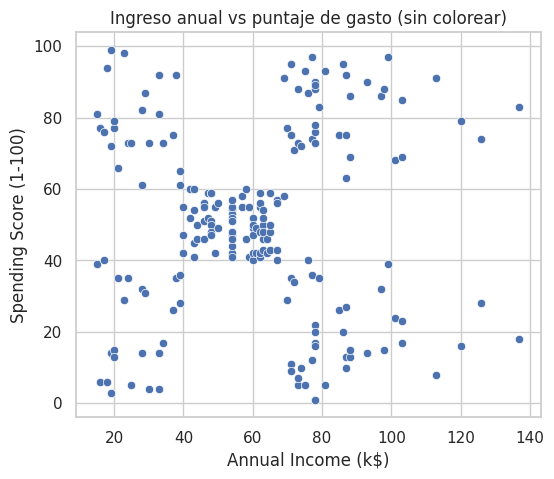

In [4]:
plt.figure(figsize=(6, 5))
sns.scatterplot(data=df, x="Annual Income (k$)", y="Spending Score (1-100)")
plt.title("Ingreso anual vs puntaje de gasto (sin colorear)")
plt.show()

### Mi hipótesis inicial
**Número de grupos que veo:** 7 (con la duda de si podrían ser 5, ver al final).

**Zonas identificadas:**
- **Centro:** ingreso medio (≈ 40–70), gasto medio (≈ 40–60). Es la zona más densa.
- **Arriba a la izquierda:** ingreso bajo (≈ 15–40), gasto alto (≈ 60–100). Hay un hueco entre gasto 60–80 en los ingresos 15–38.
- **Abajo a la izquierda:** ingreso bajo (≈ 15–40), gasto bajo (≈ 0–40).
- **Arriba a la derecha (tramo 1):** ingreso alto (≈ 70–100), gasto alto (≈ 60–100).
- **Abajo a la derecha (tramo 1):** ingreso alto (≈ 70–100), gasto bajo (≈ 0–40).
- **Arriba a la derecha (tramo 2):** ingreso muy alto (≈ 100–138), gasto alto (≈ 69–98).
- **Abajo a la derecha (tramo 2):** ingreso muy alto (≈ 100–140), gasto bajo (≈ 0–40).

**Evidencia visual que usé:**
- El centro es un bloque denso y compacto, claramente distinto de las esquinas.
- Las esquinas tienen valores de ingreso y gasto muy diferentes a los del centro, por lo que no son comparables con él.
- A los lados del centro hay vacíos sin puntos, que separan las zonas.
- Hacia la derecha (ingreso 100–140) los puntos son más escasos y dispersos.

**Duda:** los puntos de ingreso 100–140 son pocos y están muy separados entre sí. No tengo claro si forman grupos propios o si son parte de los grupos de ingreso 70–100. Si no lo son, serían 5 grupos en vez de 7

## Paso 2 · Cargar y explorar

In [5]:
print("Dimensiones:", df.shape)
print()
df.info()
print()
print("Nulos por columna:")
print(df.isna().sum())
print()
print(df.describe())
print()
print(df["Gender"].value_counts())

Dimensiones: (200, 5)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB

Nulos por columna:
CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

       CustomerID         Age  Annual Income (k$)  Spending Score (1-100)
count  200.000000  200.000000          200.000000              200.000000
mean   100.500000   38.850000           60.560000               50.200000
std     57.879185   13.969007           26.264721              

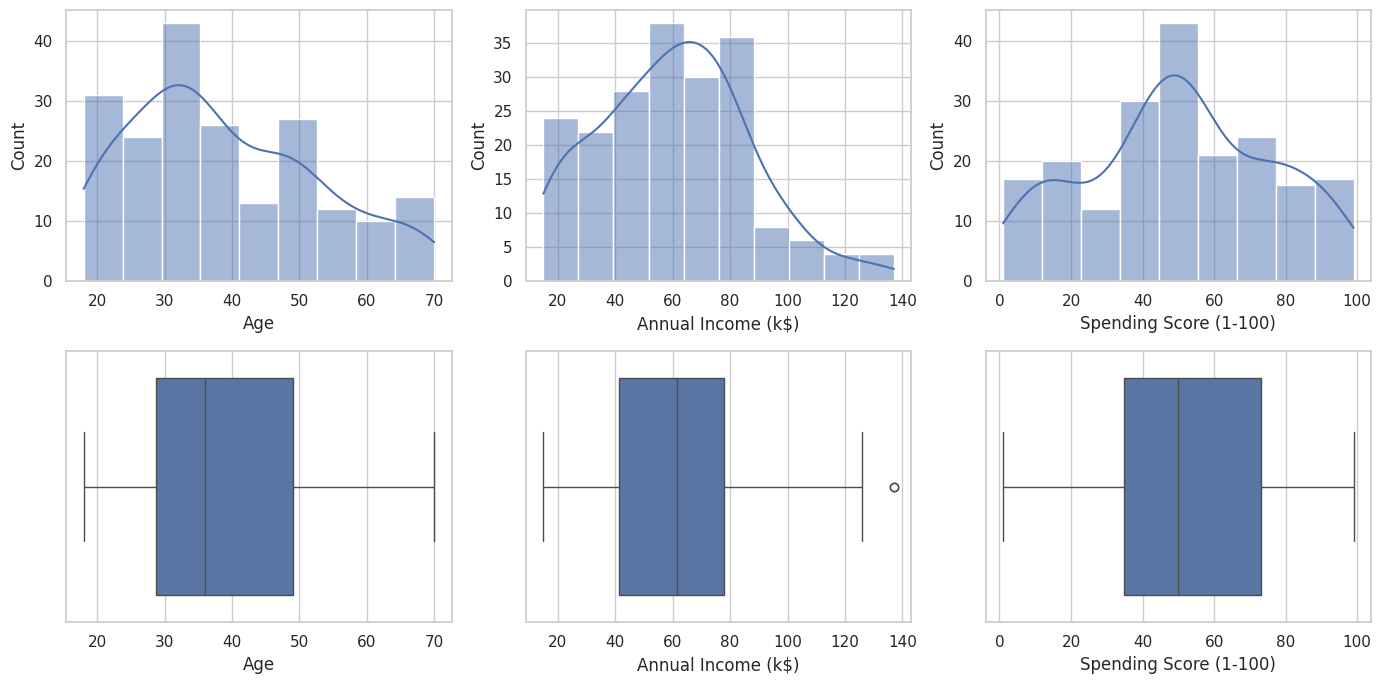

In [6]:
num_cols = ["Age", "Annual Income (k$)", "Spending Score (1-100)"]
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for i, c in enumerate(num_cols):
    sns.histplot(df[c], kde=True, ax=axes[0, i])
    sns.boxplot(x=df[c], ax=axes[1, i])
plt.tight_layout()
plt.show()

### Decisiones sobre CustomerID y Gender

- **Unidad de análisis:** cada fila representa a un cliente de la tienda (200 clientes en total), descrito por su género, edad, ingreso anual y puntaje de gasto.

- **CustomerID:** no lo incluyo en el modelo. Es solo un identificador que asigna el sistema en orden (1 a 200) y no describe el comportamiento del cliente. Si lo usara, el algoritmo consideraría "cercanos" a clientes con números de ID parecidos, lo cual no tiene ningún significado real. Lo conservo únicamente para identificar a cada cliente después.

- **Gender:** no lo incluyo en la distancia. Es una variable categórica (Female/Male). Si la codifico como 0/1, la distancia euclidiana trataría el cambio de género como una diferencia de 1 unidad, y la compararía con diferencias de ingreso o edad como si estuvieran en la misma escala. Además, una variable 0/1 solo toma dos valores y no representa una distancia gradual: dos clientes son iguales (0) o distintos (1), sin puntos intermedios. Eso le daría un peso arbitrario dentro de la distancia. Por eso la dejo fuera del modelo y la uso después, en el paso 6, para describir los grupos (por ejemplo, el porcentaje de mujeres en cada uno).

- **Variables que sí entran:** ingreso anual y puntaje de gasto (numéricas y comparables entre sí). La edad la puedo sumar más adelante.

## Paso 3 · Preparar: variables y escala

In [7]:
features = ["Annual Income (k$)", "Spending Score (1-100)"]
X_raw = df[features].copy()

rangos = pd.DataFrame({"min": X_raw.min(), "max": X_raw.max()})
rangos["rango"] = rangos["max"] - rangos["min"]
print(rangos)

scaler = StandardScaler()
X_std = pd.DataFrame(scaler.fit_transform(X_raw), columns=features, index=X_raw.index)
print()
print(X_std.describe().loc[["mean", "std"]].round(3))

                        min  max  rango
Annual Income (k$)       15  137    122
Spending Score (1-100)    1   99     98

      Annual Income (k$)  Spending Score (1-100)
mean              -0.000                  -0.000
std                1.003                   1.003


### Rango de cada variable y decisión de escala

- **Rangos antes de escalar:**
  - Annual Income (k$): mínimo 15, máximo 137 (rango 122).
  - Spending Score (1-100): mínimo 1, máximo 99 (rango 98).

- **¿Estandarizo?** Sí. Aunque los rangos de ambas variables son parecidos, K-means usa distancia euclidiana, que depende de las unidades y de la dispersión de cada variable. Estandarizar (media 0, desviación estándar 1) deja a ambas en la misma escala y evita que una pese más que la otra solo por sus unidades. Además, esto me permitirá comparar en el paso 5 los resultados con y sin estandarizar. Conservo ambas versiones: `X_raw` (original) y `X_std` (estandarizada).

- **Verificación:** tras escalar, la media de cada variable es ≈ 0 y la desviación estándar ≈ 1 (muestra 1.003 porque `describe()` usa la desviación muestral y `StandardScaler` la poblacional).

## Paso 4 · Ajustar K-means y explorar k

,k,inercia,silueta
0,2,269.6910,0.3213
1,3,157.7040,0.4666
2,4,108.9213,0.4939
3,5,65.5684,0.5547
4,6,55.0573,0.5399
5,7,44.8648,0.5281
6,8,37.2282,0.4552
7,9,32.3923,0.4571
8,10,29.9819,0.4432


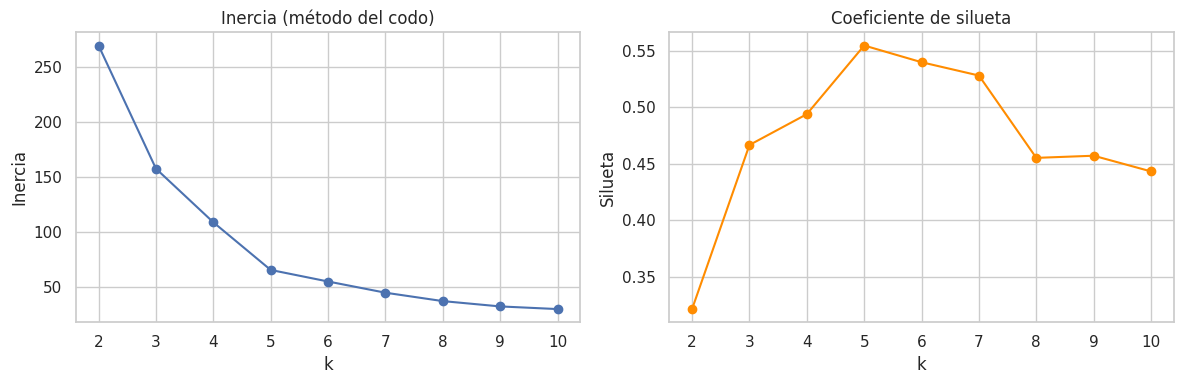

In [8]:
ks = range(2, 11)
inercia, silueta = [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(X_std)
    inercia.append(km.inertia_)
    silueta.append(silhouette_score(X_std, km.labels_))

res = pd.DataFrame({"k": list(ks), "inercia": inercia, "silueta": silueta}).round(4)
display(res)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(res["k"], res["inercia"], "o-"); ax[0].set_title("Inercia (método del codo)")
ax[0].set_xlabel("k"); ax[0].set_ylabel("Inercia")
ax[1].plot(res["k"], res["silueta"], "o-", color="darkorange"); ax[1].set_title("Coeficiente de silueta")
ax[1].set_xlabel("k"); ax[1].set_ylabel("Silueta")
plt.tight_layout(); plt.show()

###¿Por qué la inercia siempre baja al aumentar k?

La inercia es la suma de las distancias al cuadrado entre cada punto y el centroide de su grupo. Cuando aumento k, hay más centroides disponibles, así que cada punto puede quedar asignado a uno más cercano (o, en el peor caso, igual de cercano que antes). Por eso la distancia de cada punto a su centroide nunca aumenta y la inercia siempre disminuye al subir k. En los resultados pasa de 269.7 con k = 2 a 30.0 con k = 10.

En el caso extremo, con k = 200 (un centroide por cliente) cada punto sería su propio centroide, la distancia sería 0 y la inercia sería 0, sin que eso signifique que la segmentación sea buena: solo sería una lista de 200 clientes.

**Implicación para elegir k:** no puedo elegir el k con menor inercia, porque siempre sería el más grande. Solo sirve buscar el "codo", el punto donde la mejora deja de ser grande. En mi curva la caída es fuerte hasta k = 5 (de 108.9 a 65.6) y después se aplana (55.1 en k = 6, 44.9 en k = 7), pero el codo no es nítido, así que necesito más evidencia.

**Silueta:** es máxima en k = 5 (0.555) y baja después, lo que apoya k = 5 como candidato. Aun así, lo contrastaré con estabilidad y utilidad en el paso 5.

## Paso 5 · Evaluar con más de una evidencia
**(a)** estructura interna: codo y silueta (arriba). **(b)** estabilidad. **(c)** utilidad. Más el mini-experimento de escala.

,k,ARI_semillas_media,ARI_semillas_min,ARI_submuestra_media,ARI_submuestra_min
0,2,0.346,-0.001,0.392,-0.003
1,3,0.830,0.132,1.000,1.000
2,4,0.745,0.605,0.840,0.590
3,5,0.950,0.692,0.993,0.971
4,6,0.881,0.633,0.930,0.633
5,7,0.724,0.570,0.921,0.619
6,8,0.791,0.567,0.887,0.765


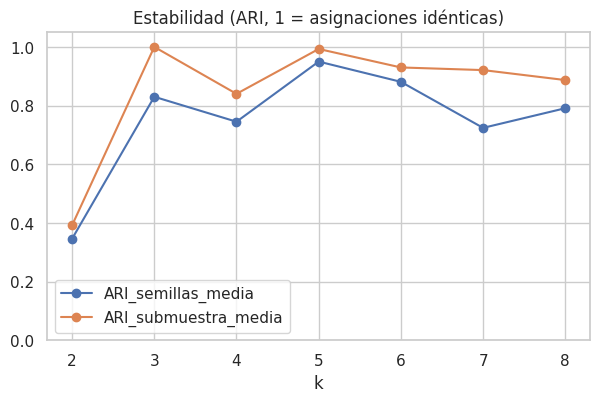

In [9]:
# (b) Estabilidad 1: distintas semillas vs una referencia
rows = []
for k in range(2, 9):
    ref = KMeans(n_clusters=k, n_init=10, random_state=0).fit(X_std).labels_
    aris = [adjusted_rand_score(ref, KMeans(n_clusters=k, n_init=1, random_state=s).fit(X_std).labels_)
            for s in range(1, 21)]
    rows.append({"k": k, "ARI_semillas_media": np.mean(aris), "ARI_semillas_min": np.min(aris)})

# (b) Estabilidad 2: ajustar en submuestras del 80% y predecir todo el conjunto
for r in rows:
    k = r["k"]
    ref = KMeans(n_clusters=k, n_init=10, random_state=0).fit(X_std).labels_
    aris = []
    for s in range(20):
        sub = X_std.sample(frac=0.8, random_state=s)
        pred = KMeans(n_clusters=k, n_init=10, random_state=s).fit(sub).predict(X_std)
        aris.append(adjusted_rand_score(ref, pred))
    r["ARI_submuestra_media"] = np.mean(aris)
    r["ARI_submuestra_min"] = np.min(aris)

estab = pd.DataFrame(rows).round(3)
display(estab)
estab.plot(x="k", y=["ARI_semillas_media", "ARI_submuestra_media"], marker="o", figsize=(7, 4),
           title="Estabilidad (ARI, 1 = asignaciones idénticas)")
plt.ylim(0, 1.05); plt.show()

ARI entre ambas particiones: 1.0
Silueta estandarizado: 0.555
Silueta sin estandarizar: 0.554

Tamaños (estandarizado): [81 39 22 35 23]
Tamaños (sin estandarizar): [81 39 22 35 23]


raw,0,1,2,3,4
std,,,,,
0,81,0,0,0,0
1,0,39,0,0,0
2,0,0,22,0,0
3,0,0,0,35,0
4,0,0,0,0,23


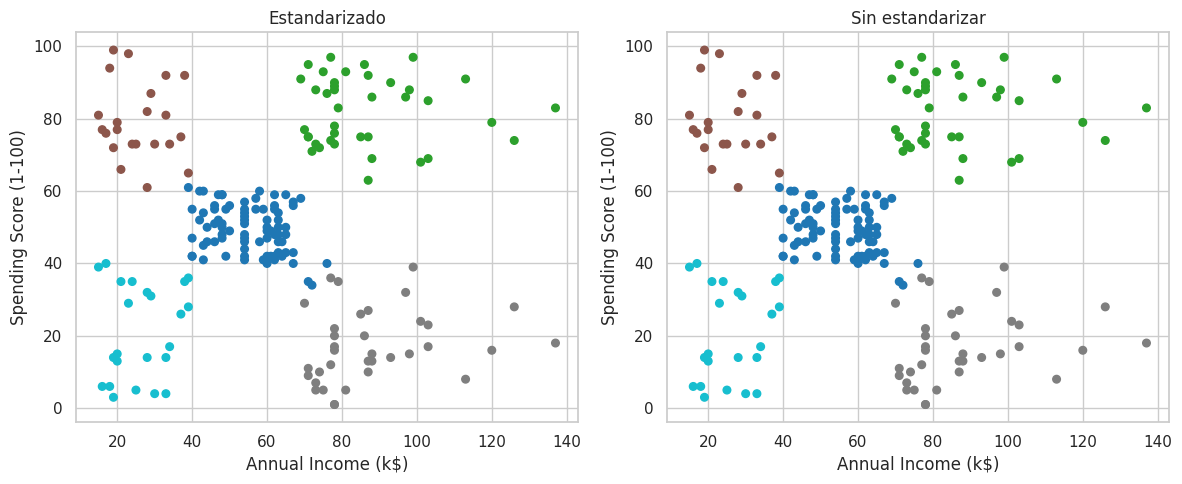

In [11]:
K_ELEGIDO = 5

# Mini-experimento de escala: mismo k, con y sin estandarizar
km_std = KMeans(n_clusters=K_ELEGIDO, n_init=10, random_state=SEED).fit(X_std)
km_raw = KMeans(n_clusters=K_ELEGIDO, n_init=10, random_state=SEED).fit(X_raw)

print("ARI entre ambas particiones:", round(adjusted_rand_score(km_std.labels_, km_raw.labels_), 3))
print("Silueta estandarizado:", round(silhouette_score(X_std, km_std.labels_), 3))
print("Silueta sin estandarizar:", round(silhouette_score(X_raw, km_raw.labels_), 3))
print()
print("Tamaños (estandarizado):", np.bincount(km_std.labels_))
print("Tamaños (sin estandarizar):", np.bincount(km_raw.labels_))
display(pd.crosstab(km_std.labels_, km_raw.labels_, rownames=["std"], colnames=["raw"]))

fig, ax = plt.subplots(1, 2, figsize=(12, 5))
for a, lab, t in zip(ax, [km_std.labels_, km_raw.labels_], ["Estandarizado", "Sin estandarizar"]):
    a.scatter(X_raw.iloc[:, 0], X_raw.iloc[:, 1], c=lab, cmap="tab10", s=30)
    a.set_title(t); a.set_xlabel(features[0]); a.set_ylabel(features[1])
plt.tight_layout(); plt.show()

### Mi elección de k y la evidencia
- **k elegido:** 5.
- **Evidencia (a) estructura interna:** la silueta es máxima en k = 5 (0.555) y baja en k = 6 (0.540) y k = 7 (0.528), por lo que no apoya mi hipótesis inicial de 7 grupos. La inercia cae de 108.9 (k = 4) a 65.6 (k = 5), una reducción de ~40 %; en k = 6 solo baja ~16 % más (55.1) y en k = 7 otro ~19 % (44.9). El codo no es perfectamente nítido, pero es más claro en k = 5 que en cualquier otro valor.
- **Evidencia (b) estabilidad:** en k = 5 el ARI entre semillas es 0.950 en promedio (mínimo 0.692) y el ARI en submuestras del 80 % es 0.993 en promedio (mínimo 0.971). Es la mejor combinación entre los k con buena silueta: k = 4 (0.745 / 0.840), k = 6 (0.881 / 0.930) y k = 7 (0.724 / 0.921) son menos estables. k = 3 tiene un ARI de submuestra perfecto (1.000), pero su silueta es más baja (0.467) y su ARI mínimo entre semillas es 0.132, es decir, algunas inicializaciones caen en soluciones muy distintas. El mínimo de 0.692 en k = 5 indica que alguna semilla aislada con `n_init=1` puede caer en un óptimo local, por eso uso `n_init=10`.
- **Evidencia (c) utilidad:** con k = 5 puedo describir cada grupo con una frase (ver tabla del paso 6) y cada uno sugiere una acción de comunicación distinta. Pasar a k = 6 o 7 dividiría grupos sin ganar una diferencia de acción clara. Con k = 3 mezclaría perfiles que requieren mensajes opuestos (por ejemplo, ingreso alto con gasto alto y con gasto bajo).

### Con vs sin estandarizar
- **¿Cambiaron las asignaciones?** No. El ARI entre ambas particiones es 1.0, los tamaños son idénticos (81, 39, 22, 35, 23) y la tabla cruzada es diagonal. La silueta casi no cambia (0.555 vs 0.554).
- **¿Qué variable dominaba al no escalar?** En teoría, la que tiene mayor dispersión domina la distancia euclidiana. Aquí el ingreso tiene rango 122 y desviación ~26.3, y el gasto rango 98 y desviación ~25.8: el ingreso pesa apenas un poco más, pero la diferencia es mínima. Por eso no esperaba cambios importantes, y eso es lo que se observa.
- **Matiz:** que escalar no haya importado aquí es una propiedad de este dataset (variables con unidades y dispersiones parecidas), no una razón para omitirlo. Si sumara `Age` (rango ~52) u otra variable con otra escala, o usara ingreso en pesos, la distancia sí cambiaría. Además, las dos siluetas se calculan en espacios distintos, así que su comparación es solo aproximada. Mantengo la estandarización como práctica segura.

## Paso 6 · Interpretar y decidir

In [12]:
df["cluster"] = KMeans(n_clusters=K_ELEGIDO, n_init=10, random_state=SEED).fit_predict(X_std)

perfil = (df.groupby("cluster")
            .agg(n=("CustomerID", "count"),
                 edad_media=("Age", "mean"),
                 ingreso_media=("Annual Income (k$)", "mean"),
                 ingreso_mediana=("Annual Income (k$)", "median"),
                 gasto_media=("Spending Score (1-100)", "mean"),
                 gasto_mediana=("Spending Score (1-100)", "median"),
                 pct_mujeres=("Gender", lambda s: (s == "Female").mean() * 100))
            .round(1))
display(perfil)

,n,edad_media,ingreso_media,ingreso_mediana,gasto_media,gasto_mediana,pct_mujeres
cluster,,,,,,,
0,81,42.7,55.3,54.0,49.5,50.0,59.3
1,39,32.7,86.5,79.0,82.1,83.0,53.8
2,22,25.3,25.7,24.5,79.4,77.0,59.1
3,35,41.1,88.2,85.0,17.1,16.0,45.7
4,23,45.2,26.3,25.0,20.9,17.0,60.9


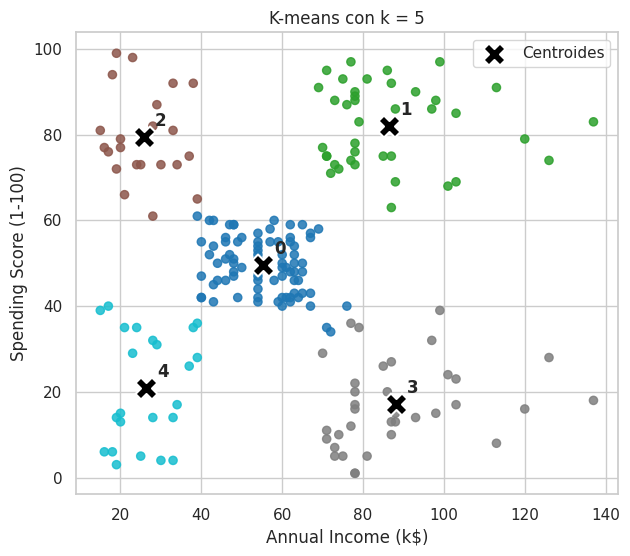

In [13]:
# Centroides en unidades originales = promedio por grupo en las variables originales
centroides = df.groupby("cluster")[features].mean()

plt.figure(figsize=(7, 6))
sc = plt.scatter(df[features[0]], df[features[1]], c=df["cluster"], cmap="tab10", s=35, alpha=0.85)
plt.scatter(centroides[features[0]], centroides[features[1]], c="black", marker="X", s=250,
            edgecolor="white", linewidth=1.5, label="Centroides")
for c, row in centroides.iterrows():
    plt.annotate(str(c), (row[features[0]], row[features[1]]), xytext=(8, 8), textcoords="offset points",
                 fontweight="bold")
plt.xlabel(features[0]); plt.ylabel(features[1]); plt.title(f"K-means con k = {K_ELEGIDO}")
plt.legend(); plt.show()

### Segmentos, nombres y acciones
Según la tabla de perfiles (una fila por cluster):

| Cluster | Perfil (ingreso / gasto / edad) | Nombre del segmento | Acción de comunicación a probar |
|---|---|---|---|
| 0 | Ingreso medio (~55 k$) / gasto medio (~50) / edad ~43. Es el grupo más grande (81 clientes) | Clientes promedio | Programa de fidelización por acumulación de puntos y ofertas por volumen para aumentar el ticket de compra |
| 1 | Ingreso alto (~87 k$) / gasto alto (~82) / edad ~33 (39 clientes) | Compradores premium | Acceso anticipado a lanzamientos, beneficios VIP y atención personalizada para retenerlos |
| 2 | Ingreso bajo (~26 k$) / gasto alto (~79) / edad ~25, el más joven (22 clientes) | Jóvenes entusiastas | Campañas en redes sociales, cupones y promociones de temporada; cuidar que no promueva un gasto excesivo |
| 3 | Ingreso alto (~88 k$) / gasto bajo (~17) / edad ~41 (35 clientes) | Ahorradores de alto potencial | Probar mensajes de calidad y exclusividad, y una encuesta corta para entender por qué compran poco; es el grupo con más espacio de crecimiento |
| 4 | Ingreso bajo (~26 k$) / gasto bajo (~21) / edad ~45, el mayor (23 clientes) | Compradores austeros | Comunicaciones de bajo costo centradas en precio y ofertas básicas; no justifican inversión alta por cliente |

### Reflexión
- **¿Coincidió mi hipótesis inicial?** Parcialmente. Vi bien las cinco zonas principales (centro y cuatro esquinas), y mi duda del final se resolvió: los puntos de ingreso 100–140 no forman grupos propios, sino que quedan dentro de los grupos de ingreso alto (clusters 1 y 3). Los 7 grupos que propuse se reducen a 5.
- **¿Qué me sorprendió?** Que estandarizar no cambió nada (ARI = 1.0) y lo estable que es k = 5 (ARI de submuestra 0.993). También que la edad, que no entró al modelo, difiere bastante entre grupos (25 años en el cluster 2 vs 45 en el 4), lo que refuerza que los segmentos tienen sentido. El género, en cambio, casi no distingue grupos (46–61 % de mujeres).
- **Limitaciones:** uso solo 2 variables; `Spending Score` es un puntaje asignado por la tienda y no un gasto observado; son datos de práctica (200 clientes); K-means asume grupos esféricos y de tamaño parecido, y asigna todos los puntos a algún grupo, aunque estén en la frontera. Los segmentos son una guía para probar acciones (por ejemplo con A/B test), no una verdad fija.

# Laboratorio · Clustering — Ejercicio 2: Clustering jerárquico para agrupar países

> Regla de lectura: un dendrograma no entrega grupos hasta que lo cortas, y su altura mide disimilitud, no calidad. Un grupo significa «estos países son cercanos bajo estas variables, esta escala, esta distancia y este enlace».

**Dataset:** Unsupervised Learning on Country Data (`rohan0301/unsupervised-learning-on-country-data`), 167 países × 10 columnas.

In [33]:
# Credenciales desde los Secretos de Colab
from google.colab import userdata
os.environ["KAGGLE_API_TOKEN"] = userdata.get("KAGGLE_API_TOKEN")

import kagglehub
path_paises = kagglehub.dataset_download("rohan0301/unsupervised-learning-on-country-data")
print("Carpeta:", path_paises)
for p in pathlib.Path(path_paises).rglob("*"):
    print(p)

Using Colab cache for faster access to the 'unsupervised-learning-on-country-data' dataset.
Carpeta: /kaggle/input/unsupervised-learning-on-country-data
/kaggle/input/unsupervised-learning-on-country-data/Country-data.csv
/kaggle/input/unsupervised-learning-on-country-data/data-dictionary.csv


In [16]:
# Ajusta el nombre si el listado anterior muestra otro
csv_paises = next(p for p in pathlib.Path(path_paises).rglob("*.csv") if p.name.lower() == "country-data.csv")
paises = pd.read_csv(csv_paises)
paises.head()

,country,child_mort,exports,health,imports,income,inflation,life_expec,total_fer,gdpp
0,Afghanistan,90.2,10.0,7.58,44.9,1610,9.44,56.2,5.82,553
1,Albania,16.6,28.0,6.55,48.6,9930,4.49,76.3,1.65,4090
2,Algeria,27.3,38.4,4.17,31.4,12900,16.10,76.5,2.89,4460
3,Angola,119.0,62.3,2.85,42.9,5900,22.40,60.1,6.16,3530
4,Antigua and Barbuda,10.3,45.5,6.03,58.9,19100,1.44,76.8,2.13,12200


## Paso 1 · Hipótesis antes de calcular

In [31]:
print(sorted(paises["country"].unique()))

['Afghanistan', 'Albania', 'Algeria', 'Angola', 'Antigua and Barbuda', 'Argentina', 'Armenia', 'Australia', 'Austria', 'Azerbaijan', 'Bahamas', 'Bahrain', 'Bangladesh', 'Barbados', 'Belarus', 'Belgium', 'Belize', 'Benin', 'Bhutan', 'Bolivia', 'Bosnia and Herzegovina', 'Botswana', 'Brazil', 'Brunei', 'Bulgaria', 'Burkina Faso', 'Burundi', 'Cambodia', 'Cameroon', 'Canada', 'Cape Verde', 'Central African Republic', 'Chad', 'Chile', 'China', 'Colombia', 'Comoros', 'Congo, Dem. Rep.', 'Congo, Rep.', 'Costa Rica', "Cote d'Ivoire", 'Croatia', 'Cyprus', 'Czech Republic', 'Denmark', 'Dominican Republic', 'Ecuador', 'Egypt', 'El Salvador', 'Equatorial Guinea', 'Eritrea', 'Estonia', 'Fiji', 'Finland', 'France', 'Gabon', 'Gambia', 'Georgia', 'Germany', 'Ghana', 'Greece', 'Grenada', 'Guatemala', 'Guinea', 'Guinea-Bissau', 'Guyana', 'Haiti', 'Hungary', 'Iceland', 'India', 'Indonesia', 'Iran', 'Iraq', 'Ireland', 'Israel', 'Italy', 'Jamaica', 'Japan', 'Jordan', 'Kazakhstan', 'Kenya', 'Kiribati', 'Kuwa

In [32]:
americas = ["Argentina", "Bolivia", "Brazil", "Chile", "Colombia", "Costa Rica", "Dominican Republic",
            "Ecuador", "El Salvador", "Guatemala", "Haiti", "Jamaica", "Mexico", "Panama", "Paraguay",
            "Peru", "Uruguay", "Venezuela", "Canada", "United States"]
print("No encontrados en el dataset:", [p for p in americas if p not in set(paises["country"])])

N_TOTAL = 35
base_am = paises[paises["country"].isin(americas)]
resto = paises[~paises["country"].isin(americas)]
extra = resto.sample(n=max(0, N_TOTAL - len(base_am)), random_state=SEED)

muestra = pd.concat([base_am, extra]).set_index("country")
assert "Chile" in muestra.index, "Chile no está en el subconjunto"
print(len(muestra), "países en el subconjunto:")
print(sorted(muestra.index))

No encontrados en el dataset: ['Mexico']
35 países en el subconjunto:
['Argentina', 'Bahamas', 'Barbados', 'Bolivia', 'Botswana', 'Brazil', 'Canada', 'Cape Verde', 'Chile', 'Colombia', 'Congo, Dem. Rep.', 'Costa Rica', 'Dominican Republic', 'Ecuador', 'El Salvador', 'Grenada', 'Guatemala', 'Haiti', 'Jamaica', 'Kazakhstan', 'Kenya', 'Libya', 'Malawi', 'Nepal', 'Panama', 'Paraguay', 'Peru', 'Philippines', 'St. Vincent and the Grenadines', 'Tonga', 'Uganda', 'United States', 'Uruguay', 'Vanuatu', 'Venezuela']


### Mi hipótesis inicial
**Criterio de selección del subconjunto:** incluí a Chile y otros 18 países de América
elegidos manualmente (19 en total: Sudamérica, Centroamérica, el Caribe, Canadá y Estados
Unidos; México no aparece en el dataset) y completé hasta 35 países con 16 elegidos al
azar del resto del mundo (muestra reproducible, `random_state=42`). La muestra aleatoria
incluyó además a Bahamas, Barbados y Grenada, por lo que la presencia de países americanos
no se limita a la lista manual. Con esto puedo comparar a Chile con sus vecinos regionales
y con países de otras regiones y niveles de desarrollo, sin que el dendrograma quede
ilegible.

**Países con los que creo que se agrupará Chile:** Uruguay, Argentina, Costa Rica y
Panamá serían sus vecinos más cercanos. A un nivel más alto de la jerarquía espero que se
sumen Brasil, Colombia y Ecuador, y también Barbados, Bahamas y Kazajistán, países de
ingreso medio-alto de otras regiones. Espero que Canadá y Estados Unidos formen un grupo
aparte, de ingreso mucho más alto, y que Haití, Malawi, Nepal, Kenia y Congo (Rep. Dem.)
queden en el extremo opuesto.

**Evidencia / razonamiento que usé:** Chile es un país de ingreso medio-alto, con baja
mortalidad infantil, alta esperanza de vida y baja fecundidad, un perfil parecido al del
Cono Sur y al de Costa Rica. Creo que `income`, `gdpp`, `life_expec`, `child_mort` y
`total_fer` serán las variables que más pesen en la cercanía, porque son las que mejor
separan países por nivel de desarrollo.

**Duda:** no sé si Canadá y Estados Unidos quedarán realmente separados de Chile, ni si
variables como `exports`, `imports` e `inflation` (que no siguen el orden de desarrollo)
harán que países con perfil de salud e ingreso parecido queden en grupos distintos. Tampoco
sé si, sin estandarizar, `income` y `gdpp` dominarán la distancia y harán que todo lo demás
importe poco.

## Paso 2 · Cargar y explorar

In [19]:
variables = ["child_mort", "exports", "health", "imports", "income", "inflation", "life_expec", "total_fer", "gdpp"]

print("Dimensiones:", paises.shape)
print()
paises.info()
print()
print("Nulos por columna:")
print(paises.isna().sum())
print("Países duplicados:", paises["country"].duplicated().sum())
print()
print(paises[variables].describe().round(2))

Dimensiones: (167, 10)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 167 entries, 0 to 166
Data columns (total 10 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   country     167 non-null    object 
 1   child_mort  167 non-null    float64
 2   exports     167 non-null    float64
 3   health      167 non-null    float64
 4   imports     167 non-null    float64
 5   income      167 non-null    int64  
 6   inflation   167 non-null    float64
 7   life_expec  167 non-null    float64
 8   total_fer   167 non-null    float64
 9   gdpp        167 non-null    int64  
dtypes: float64(7), int64(2), object(1)
memory usage: 13.2+ KB

Nulos por columna:
country       0
child_mort    0
exports       0
health        0
imports       0
income        0
inflation     0
life_expec    0
total_fer     0
gdpp          0
dtype: int64
Países duplicados: 0

       child_mort  exports  health  imports     income  inflation  life_expec  \
count      167.00   

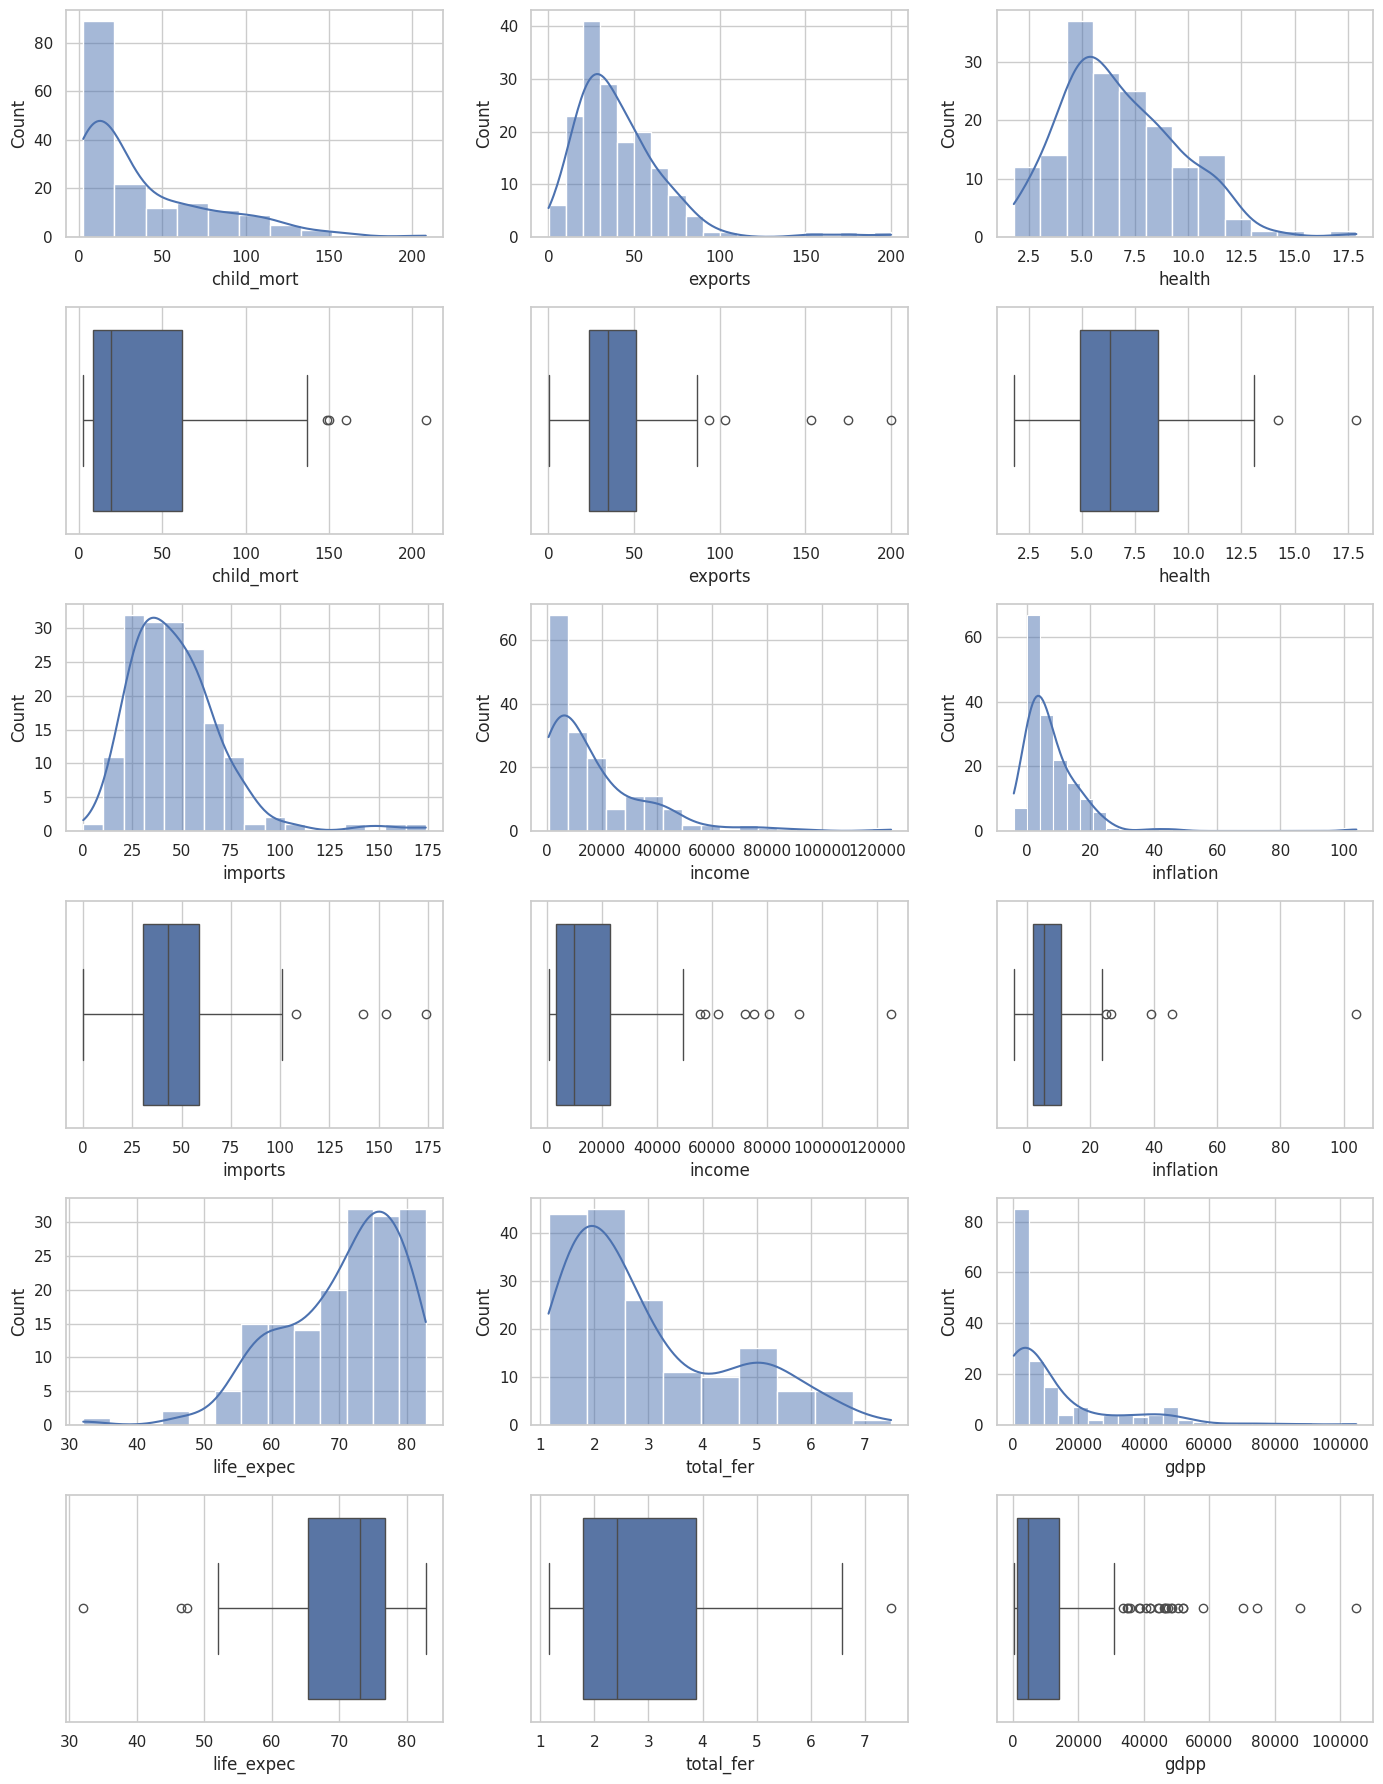

In [20]:
fig, axes = plt.subplots(6, 3, figsize=(14, 18))
for i, v in enumerate(variables):
    r, c = (i // 3) * 2, i % 3
    sns.histplot(paises[v], kde=True, ax=axes[r, c])
    sns.boxplot(x=paises[v], ax=axes[r + 1, c])
plt.tight_layout()
plt.show()

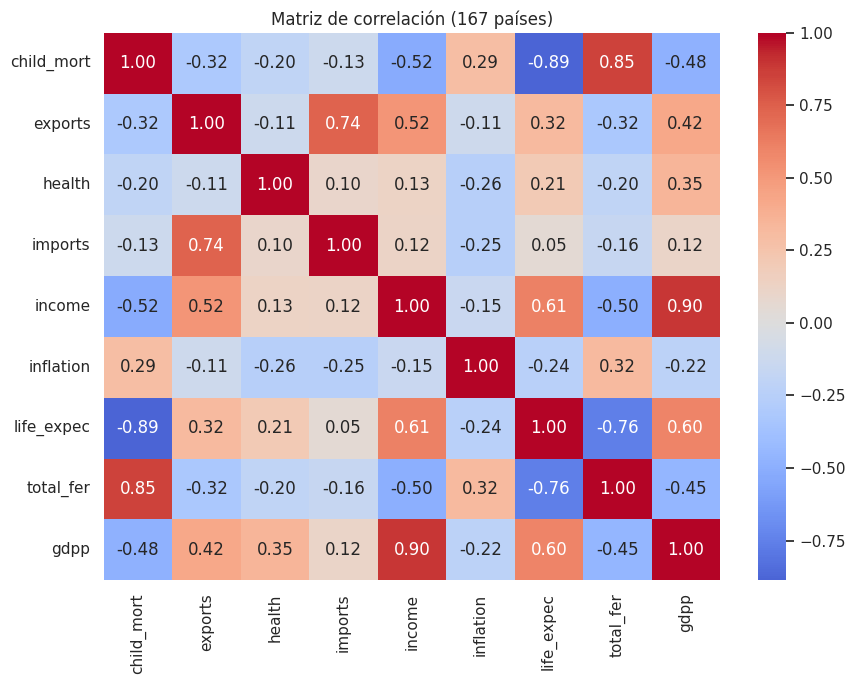

In [21]:
plt.figure(figsize=(9, 7))
sns.heatmap(paises[variables].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Matriz de correlación (167 países)")
plt.tight_layout(); plt.show()

### Decisiones sobre `country` y las variables

- **Unidad de análisis:** cada fila representa a un país (167 en total), descrito por 9 indicadores socioeconómicos y de salud. No hay nulos ni países duplicados. En el subconjunto trabajo con 35 países.

- **country:** no la incluyo en la distancia. Es el nombre del país, una etiqueta y no una medida, así que no tiene sentido calcular distancias entre nombres. La uso como índice del DataFrame para rotular el dendrograma y listar los grupos.

- **Variables que entran:** uso las 9 (`child_mort`, `exports`, `health`, `imports`, `income`, `inflation`, `life_expec`, `total_fer`, `gdpp`), porque el enunciado las presenta como los indicadores del problema y no hay una razón para descartar alguna. Dejo declarado que varias están muy correlacionadas (matriz de correlación): `income` con `gdpp` (0.90), `child_mort` con `life_expec` (−0.89) y con `total_fer` (0.85), `life_expec` con `total_fer` (−0.76) y `exports` con `imports` (0.74). Esto significa que algunas dimensiones, sobre todo la de nivel de desarrollo (ingreso, salud infantil, fecundidad y esperanza de vida), pesan más en la distancia porque las miden varias variables a la vez. En cambio, `health` e `inflation` tienen correlaciones bajas con casi todo y aportan información distinta.

- **Magnitudes y unidades:** las variables no miden lo mismo ni tienen el mismo orden de magnitud. `income` y `gdpp` están en dólares por persona (`income` va de 609 a 125.000 y `gdpp` de 231 a 105.000, con desviaciones estándar de ≈ 19.300 y ≈ 18.300), mientras que el resto está en porcentajes, años, tasas o hijos por mujer, con desviaciones de entre ≈ 1.5 y 41 (por ejemplo, `child_mort` ≈ 40, `exports` ≈ 27, `total_fer` ≈ 1.5). Sin preparar los datos, `income` y `gdpp` dominarían una distancia euclidiana de lejos, y las otras 7 variables casi no influirían. Lo contrasto en el paso 3 y 4.

- **Distribuciones y atípicos:** `child_mort`, `income`, `gdpp`, `inflation` y `total_fer` son asimétricas hacia la derecha (la mayoría de los países tiene valores bajos y unos pocos, muy altos). `exports`, `imports` e `inflation` tienen atípicos extremos (hasta 200, 174 y 104 respectivamente), y `life_expec` tiene unos pocos valores muy bajos (hasta ≈ 32 años). Estos países atípicos pueden aislarse como hojas sueltas o formar grupos propios en el dendrograma, sobre todo con el enlace `single`. No los elimino, porque son países reales y no errores de medición, pero lo tengo en cuenta al interpretar.

## Paso 3 · Preparar: variables y escala

In [22]:
X_raw_p = muestra[variables].copy()          # valores originales
scaler_p = StandardScaler()
X_std_p = pd.DataFrame(scaler_p.fit_transform(X_raw_p), columns=variables, index=X_raw_p.index)   # estandarizada
etiquetas = list(X_raw_p.index)              # nombres de países, separados de la matriz numérica

rangos_p = pd.DataFrame({"min": X_raw_p.min(), "max": X_raw_p.max(), "desv_est": X_raw_p.std(ddof=0)})
rangos_p["rango"] = rangos_p["max"] - rangos_p["min"]
print(rangos_p.round(2))

print()
print(X_std_p.describe().loc[["mean", "std"]].round(3))

               min       max  desv_est     rango
child_mort    5.60    208.00     38.34    202.40
exports       9.58     70.00     14.16     60.42
health        3.61     17.90      2.68     14.29
imports      11.80     78.20     15.24     66.40
income      609.00  49400.00  10570.55  48791.00
inflation    -0.39     45.90      8.55     46.29
life_expec   32.10     81.30      9.60     49.20
total_fer     1.63      6.54      1.15      4.91
gdpp        334.00  48400.00  11102.51  48066.00

      child_mort  exports  health  imports  income  inflation  life_expec  \
mean      -0.000   -0.000   0.000    0.000  -0.000      0.000      -0.000   
std        1.015    1.015   1.015    1.015   1.015      1.015       1.015   

      total_fer   gdpp  
mean     -0.000 -0.000  
std       1.015  1.015  


### Rango de cada variable y decisión de escala

- **Rangos antes de escalar:** en el subconjunto de 35 países, `income` va de 609 a 49.400 (desviación estándar ≈ 10.571) y `gdpp` de 334 a 48.400 (desv. ≈ 11.103). En cambio `health` va de 3,61 a 17,90 (desv. ≈ 2,68) y `total_fer` de 1,63 a 6,54 (desv. ≈ 1,15). Las otras variables están en un punto intermedio: `child_mort` (5,6–208; desv. ≈ 38,3), `exports` (desv. ≈ 14,2), `imports` (desv. ≈ 15,2), `inflation` (desv. ≈ 8,6) y `life_expec` (desv. ≈ 9,6). La desviación de `income` es unas 9.000 veces la de `total_fer`.

- **¿Estandarizo?** Sí. El enlace usa distancia euclidiana, que suma diferencias al cuadrado en las unidades originales. `income` y `gdpp` están en dólares y tienen desviaciones de miles, mientras que el resto está en porcentajes, años, tasas o hijos por mujer, con desviaciones de entre 1 y 40. Sin escalar, la distancia entre dos países sería casi solo la diferencia de ingreso y PIB per cápita, y las otras 7 variables no influirían. Al estandarizar (media 0, desv. 1), las 9 variables pesan en la misma escala. Conservo ambas versiones: `X_raw_p` (original) y `X_std_p` (estandarizada), porque en el paso 4 voy a comparar los dendrogramas con y sin estandarizar.

- **Mi predicción (escrita ANTES del paso 4):** creo que al estandarizar el dendrograma **cambiará** bastante, porque sin estandarizar `income` y `gdpp` dominarían la distancia y los países quedarían ordenados casi solo por ingreso, mientras que al estandarizar entrarían también la mortalidad infantil, la fecundidad, la esperanza de vida y el gasto en salud.

- **Verificación:** tras escalar, la media de cada variable es ≈ 0 y la desviación estándar ≈ 1 (en la tabla sale 1,015 porque `describe()` usa la desviación muestral y `StandardScaler` la poblacional, por eso el valor es ligeramente mayor que 1).

## Paso 4 · Construir la jerarquía y leer el dendrograma

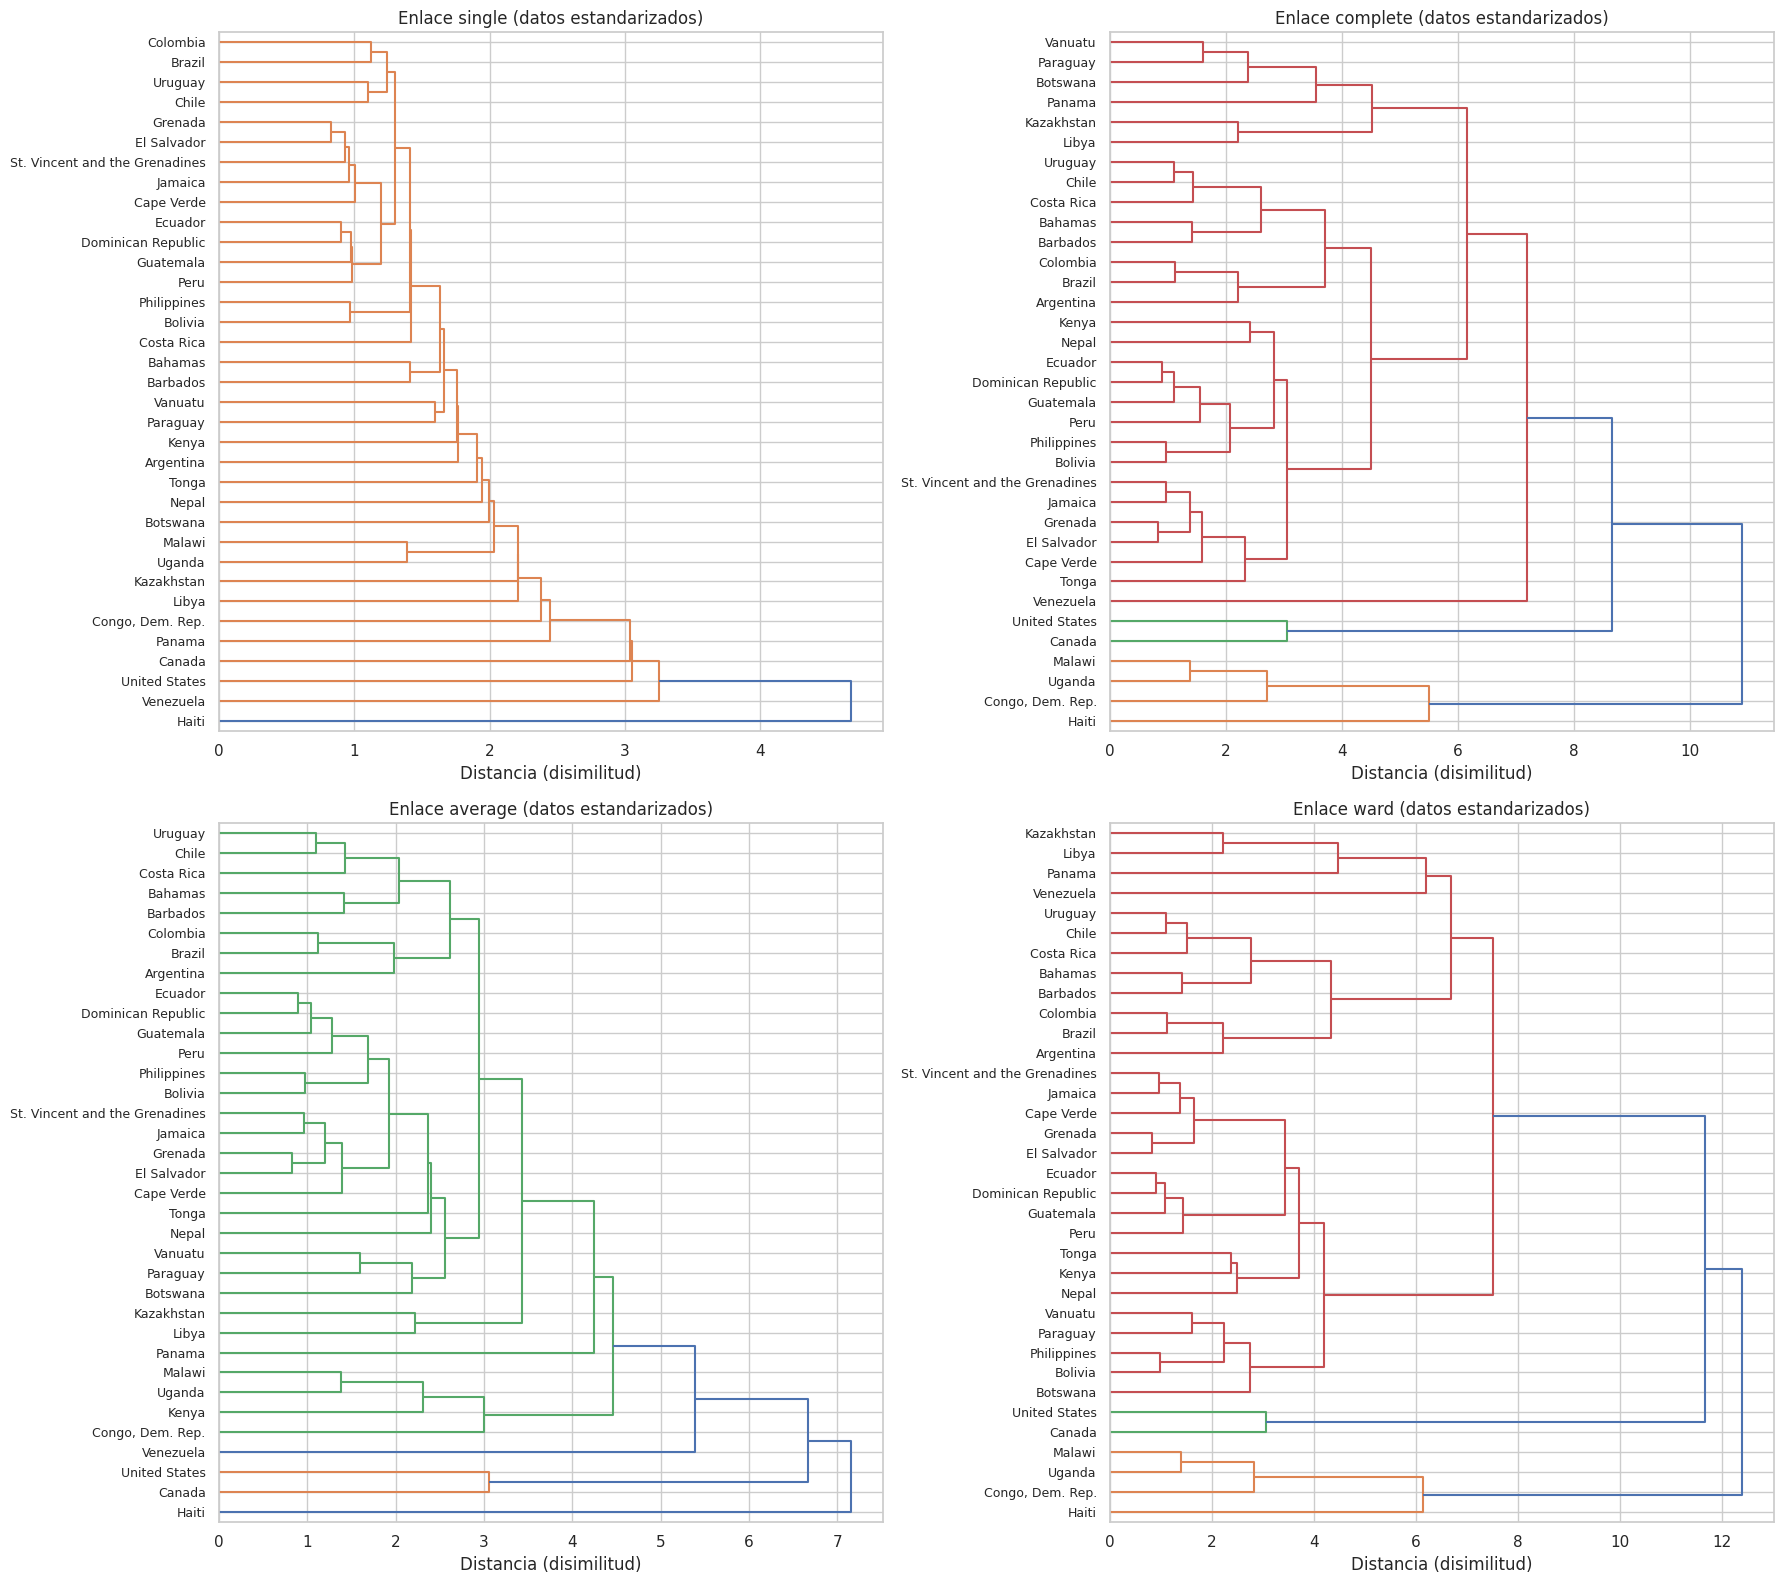

In [23]:
metodos = ["single", "complete", "average", "ward"]
Z = {}
fig, axes = plt.subplots(2, 2, figsize=(18, 16))
for ax, m in zip(axes.ravel(), metodos):
    Z[m] = linkage(X_std_p.values, method=m)          # ward solo admite distancia euclidiana
    dendrogram(Z[m], labels=etiquetas, orientation="right", leaf_font_size=9, ax=ax)
    ax.set_title(f"Enlace {m} (datos estandarizados)"); ax.set_xlabel("Distancia (disimilitud)")
plt.tight_layout(); plt.show()

In [24]:
# Correlación cofenética: qué tan fielmente cada dendrograma conserva las distancias originales
d_std = pdist(X_std_p.values)
coph = pd.DataFrame({"cofenética": [cophenet(Z[m], d_std)[0] for m in metodos]}, index=metodos).round(3)
display(coph)

,cofenética
single,0.812
complete,0.766
average,0.877
ward,0.764


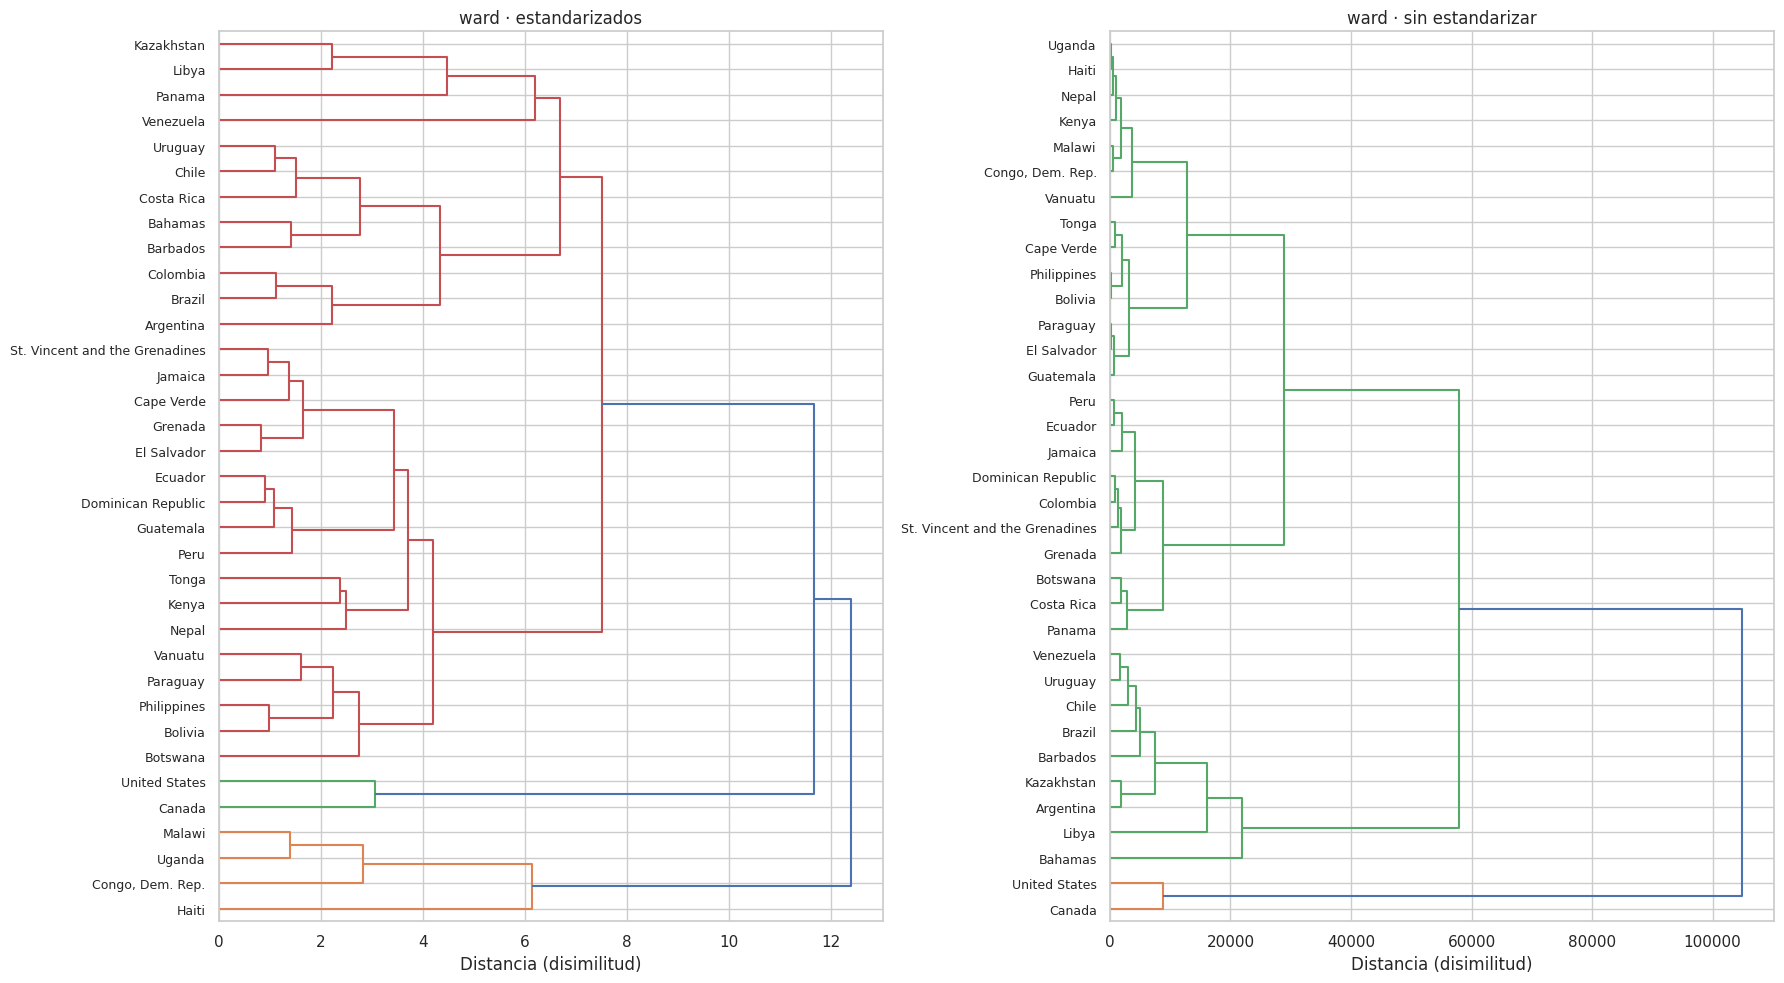

In [25]:
# Mismo enlace con los datos SIN estandarizar
METODO = "ward"     # cambia si prefieres otro enlace
Z_raw = linkage(X_raw_p.values, method=METODO)

fig, axes = plt.subplots(1, 2, figsize=(18, 10))
dendrogram(Z[METODO], labels=etiquetas, orientation="right", leaf_font_size=9, ax=axes[0])
axes[0].set_title(f"{METODO} · estandarizados"); axes[0].set_xlabel("Distancia (disimilitud)")
dendrogram(Z_raw, labels=etiquetas, orientation="right", leaf_font_size=9, ax=axes[1])
axes[1].set_title(f"{METODO} · sin estandarizar"); axes[1].set_xlabel("Distancia (disimilitud)")
plt.tight_layout(); plt.show()

### Lectura de los dendrogramas

- **Diferencias de forma entre los cuatro enlaces:**
  - `single`: forma una "escalera" típica de encadenamiento. Casi todos los países se van pegando de uno en uno a un bloque que crece, a alturas entre ≈ 1 y 3. Los países atípicos (Haití, Venezuela, Estados Unidos, Canadá) quedan como hojas sueltas que se unen al final. Casi no separa grupos y no sirve para describirlos.
  - `complete`: da grupos más compactos y bien separados. Aparecen claramente el grupo Haití, Congo, Uganda y Malawi (se une a ≈ 5,5), el par Estados Unidos y Canadá (≈ 3) y un bloque grande. Venezuela queda aislado y se une tarde (≈ 7,2). La fusión final ocurre a ≈ 11.
  - `average`: es un punto intermedio entre los dos anteriores. Separa el bloque grande donde está Chile, pero deja a Venezuela y a Haití como hojas aisladas que se unen muy arriba (≈ 5,4 y ≈ 7,2), y Congo, Uganda, Malawi y Kenya forman un grupo propio a ≈ 3.
  - `ward`: produce ramas más equilibradas y fáciles de cortar. Hay una separación muy marcada en tres bloques: Haití, Congo, Uganda y Malawi (≈ 6,1), Estados Unidos y Canadá (≈ 3) y el bloque grande, que a su vez se parte en dos subramas a ≈ 7,5. Las fusiones finales ocurren a ≈ 11,7 y ≈ 12,4.

- **Correlación cofenética:** `average` es la más alta (0,877), seguida de `single` (0,812), `complete` (0,766) y `ward` (0,764). Esto significa que `average` es el enlace que mejor conserva las distancias originales entre pares de países. Pero una cofenética alta no implica que sea el más útil: `single` tiene una cofenética alta y su dendrograma es una cadena que no permite describir grupos. `ward` tiene la más baja, pero es el que da ramas más claras y fáciles de interpretar.

- **Con vs sin estandarizar:** sí cambió la estructura. Sin estandarizar las alturas llegan a ≈ 100.000 (frente a ≈ 12 con escala), señal de que la distancia está medida casi en dólares. El orden de los países sigue el ingreso: Estados Unidos y Canadá se separan del resto y el bloque grande se parte entre países de ingreso más alto (Venezuela, Uruguay, Chile, Brasil, Barbados, Kazajistán, Argentina, Libia, Bahamas) y el resto. Haití, Congo, Uganda y Malawi dejan de formar un grupo propio y se mezclan con Nepal, Kenia y Vanuatu, porque su diferencia en mortalidad infantil, fecundidad y esperanza de vida casi no pesa. Las variables que dominaban eran `income` y `gdpp`, como anticipé en el paso 2 (desviaciones ≈ 10.500 y ≈ 11.100 frente a ≤ 38 de las demás).

- **¿Se cumplió mi predicción del paso 3?** Sí. Predije que la estructura cambiaría porque `income` y `gdpp` dominarían la distancia, y eso se observa: sin escalar, el dendrograma se vuelve casi un ordenamiento por ingreso.


## Paso 5 · Cortar la jerarquía

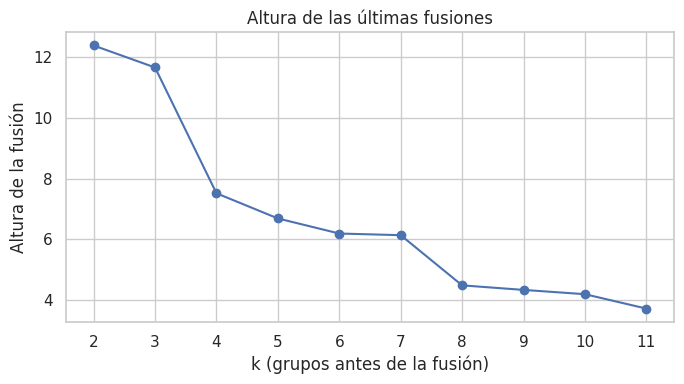

,silueta,tamaños,altura de la fusión k→k-1
k,,,
2,0.389,"[4, 31]",12.393
3,0.416,"[4, 2, 29]",11.666
4,0.226,"[4, 2, 17, 12]",7.516
5,0.229,"[4, 2, 17, 8, 4]",6.685


In [36]:
Zc = Z[METODO]


alturas = Zc[::-1, 2][:10]                      # alturas de las 10 últimas fusiones (de mayor a menor)
ks_h = np.arange(2, 2 + len(alturas))             # fusión que reduce de k grupos a k-1
plt.figure(figsize=(7, 4))
plt.plot(ks_h, alturas, "o-"); plt.xticks(ks_h)
plt.xlabel("k (grupos antes de la fusión)"); plt.ylabel("Altura de la fusión")
plt.title("Altura de las últimas fusiones")
plt.tight_layout(); plt.show()


filas = []
for k in range(2, 6):
    lab = fcluster(Zc, t=k, criterion="maxclust")
    filas.append({"k": k, "silueta": silhouette_score(X_std_p.values, lab),
                  "tamaños": np.bincount(lab)[1:].tolist(),
                  "altura de la fusión k→k-1": Zc[-(k - 1), 2]})
res_corte = pd.DataFrame(filas).set_index("k").round(3)
display(res_corte)

In [34]:
for k in range(2, 6):
    lab = pd.Series(fcluster(Zc, t=k, criterion="maxclust"), index=X_std_p.index)
    companeros = lab[lab == lab["Chile"]].index.drop("Chile").tolist()
    print(f"k={k}: grupo de Chile ({len(companeros) + 1} países) →", companeros)

k=2: grupo de Chile (31 países) → ['Argentina', 'Bolivia', 'Brazil', 'Canada', 'Colombia', 'Costa Rica', 'Dominican Republic', 'Ecuador', 'El Salvador', 'Guatemala', 'Jamaica', 'Panama', 'Paraguay', 'Peru', 'United States', 'Uruguay', 'Venezuela', 'St. Vincent and the Grenadines', 'Grenada', 'Botswana', 'Philippines', 'Barbados', 'Libya', 'Bahamas', 'Cape Verde', 'Nepal', 'Vanuatu', 'Kenya', 'Tonga', 'Kazakhstan']
k=3: grupo de Chile (29 países) → ['Argentina', 'Bolivia', 'Brazil', 'Colombia', 'Costa Rica', 'Dominican Republic', 'Ecuador', 'El Salvador', 'Guatemala', 'Jamaica', 'Panama', 'Paraguay', 'Peru', 'Uruguay', 'Venezuela', 'St. Vincent and the Grenadines', 'Grenada', 'Botswana', 'Philippines', 'Barbados', 'Libya', 'Bahamas', 'Cape Verde', 'Nepal', 'Vanuatu', 'Kenya', 'Tonga', 'Kazakhstan']
k=4: grupo de Chile (12 países) → ['Argentina', 'Brazil', 'Colombia', 'Costa Rica', 'Panama', 'Uruguay', 'Venezuela', 'Barbados', 'Libya', 'Bahamas', 'Kazakhstan']
k=5: grupo de Chile (8 país

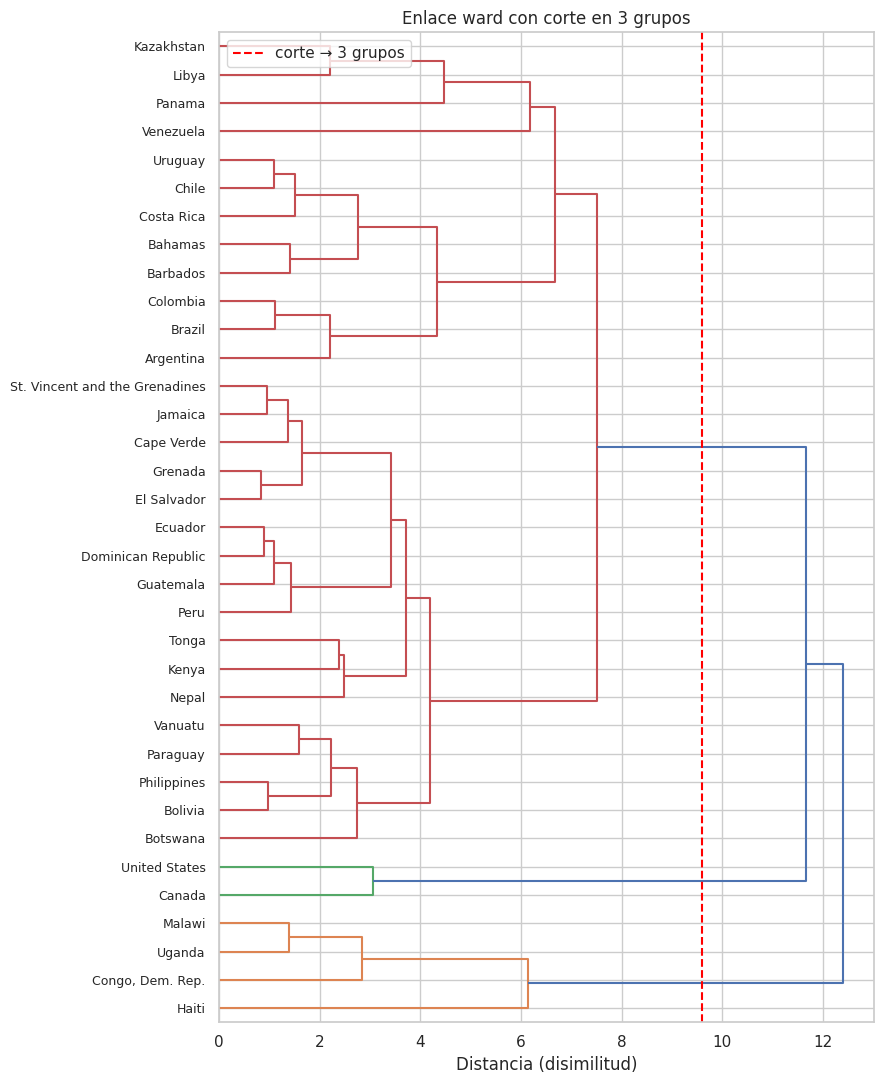

In [35]:
K_CORTE = 3
corte = (Zc[-K_CORTE, 2] + Zc[-(K_CORTE - 1), 2]) / 2     # altura entre las dos fusiones que separan k de k-1 grupos

plt.figure(figsize=(9, 11))
dendrogram(Zc, labels=etiquetas, orientation="right", leaf_font_size=9, color_threshold=corte)
plt.axvline(corte, color="red", ls="--", label=f"corte → {K_CORTE} grupos")
plt.xlabel("Distancia (disimilitud)"); plt.title(f"Enlace {METODO} con corte en {K_CORTE} grupos")
plt.legend(); plt.tight_layout(); plt.show()

### Mi elección de corte y la evidencia

- **Enlace elegido:** `ward` y **corte elegido:** k = 3.
- **Evidencia (a) saltos de altura:** las últimas fusiones están a 12,39 (2 a 1 grupo), 11,67 (3 a 2) y 7,52 (4 a 3). El mayor salto es entre 11,67 y 7,52 (≈ 4,2): hay una gran distancia entre pasar de 4 a 3 grupos y de 3 a 2, y cortar en k = 3 queda en esa zona sin fusiones intermedias. Después de k = 4 las alturas bajan despacio (6,69; 6,2; 6,1), sin saltos claros hasta k = 8. Recuerdo que la altura mide disimilitud, no calidad: un salto grande indica que se unen cosas muy distintas, no que la partición sea buena.
- **Evidencia (b) silueta:** k = 2: 0,389; **k = 3: 0,416 (máxima)**; k = 4: 0,226; k = 5: 0,229. La diferencia entre k = 2 y k = 3 es pequeña (0,027), pero hay una caída fuerte al pasar a k = 4 y k = 5, que indica que partir el bloque grande da grupos poco separados. Aun así, 0,416 es un valor moderado, no una estructura fuerte.
- **Evidencia (c) utilidad:** con k = 3 puedo describir cada grupo con una frase (países de ingreso muy bajo, países de ingreso alto y países de ingreso medio), pero el tercer grupo reúne 29 de los 35 países y mezcla casos muy distintos (Bahamas y Nepal, por ejemplo). Chile queda en ese grupo grande. Con k = 4 Chile queda con Argentina, Brasil, Colombia, Costa Rica, Panamá, Uruguay, Venezuela, Barbados, Libia, Bahamas y Kazajistán (11 países), y con k = 5 con Argentina, Brasil, Colombia, Costa Rica, Uruguay, Barbados y Bahamas (7 países), grupos más informativos para la pregunta sobre Chile. Dentro de la rama de Chile, primero se une con Uruguay (≈ 1,1), luego Costa Rica (≈ 1,5), después Bahamas y Barbados (≈ 2,7), luego Colombia, Brasil y Argentina (≈ 4,3), y recién a ≈ 6,7 se suman Kazajistán, Libia, Panamá y Venezuela.
- **¿Por qué no otro k?** k = 2 deja a Estados Unidos y Canadá mezclados con el resto, perdiendo el grupo de ingreso alto, con una silueta menor. k = 4 y k = 5 tienen una silueta casi la mitad (≈ 0,23) y grupos pequeños (de 2 y 4 países), por lo que las divisiones adicionales no son claras. Uso k = 3 como corte principal, y recurro a las subramas de k = 4 y k = 5 solo para leer con quién se parece Chile dentro del grupo grande.


## Paso 6 · Interpretar y comparar con K-means

In [40]:
muestra["cluster_jer"] = fcluster(Zc, t=K_CORTE, criterion="maxclust")

for g, d in muestra.groupby("cluster_jer"):
    print(f"Grupo {g} (n={len(d)}):", ", ".join(sorted(d.index)))

# Perfil en unidades originales
perfil_jer = (muestra.groupby("cluster_jer")
            .agg(n=("child_mort", "count"),
                 **{f"{v}_media": (v, "mean") for v in variables},
                 ingreso_mediana=("income", "median"),
                 gdpp_mediana=("gdpp", "median"))
            .round(1))
display(perfil_jer.T)

g_chile = muestra.loc["Chile", "cluster_jer"]
print()
print("Chile está en el grupo", g_chile, "junto a:", sorted(muestra[muestra["cluster_jer"] == g_chile].index.drop("Chile")))

Grupo 1 (n=4): Congo, Dem. Rep., Haiti, Malawi, Uganda
Grupo 2 (n=2): Canada, United States
Grupo 3 (n=29): Argentina, Bahamas, Barbados, Bolivia, Botswana, Brazil, Cape Verde, Chile, Colombia, Costa Rica, Dominican Republic, Ecuador, El Salvador, Grenada, Guatemala, Jamaica, Kazakhstan, Kenya, Libya, Nepal, Panama, Paraguay, Peru, Philippines, St. Vincent and the Grenadines, Tonga, Uruguay, Vanuatu, Venezuela


cluster_jer,1,2,3
n,4.0,2.0,29.0
child_mort_media,123.9,6.4,24.5
exports_media,24.1,20.8,32.3
health_media,7.6,14.6,6.4
imports_media,44.4,23.4,39.5
income_media,1169.8,45050.0,11612.8
inflation_media,12.2,2.0,7.9
life_expec_media,49.9,80.0,72.8
total_fer_media,5.3,1.8,2.6
gdpp_media,512.5,47900.0,7303.8



Chile está en el grupo 3 junto a: ['Argentina', 'Bahamas', 'Barbados', 'Bolivia', 'Botswana', 'Brazil', 'Cape Verde', 'Colombia', 'Costa Rica', 'Dominican Republic', 'Ecuador', 'El Salvador', 'Grenada', 'Guatemala', 'Jamaica', 'Kazakhstan', 'Kenya', 'Libya', 'Nepal', 'Panama', 'Paraguay', 'Peru', 'Philippines', 'St. Vincent and the Grenadines', 'Tonga', 'Uruguay', 'Vanuatu', 'Venezuela']


In [42]:
muestra["cluster_km"] = KMeans(n_clusters=K_CORTE, n_init=10, random_state=SEED).fit_predict(X_std_p.values)

display(pd.crosstab(muestra["cluster_jer"], muestra["cluster_km"], rownames=["Jerárquico"], colnames=["K-means"]))
print("ARI (jerárquico vs K-means):", round(adjusted_rand_score(muestra["cluster_jer"], muestra["cluster_km"]), 3))
print("Silueta jerárquico:", round(silhouette_score(X_std_p.values, muestra["cluster_jer"]), 3))
print("Silueta K-means:", round(silhouette_score(X_std_p.values, muestra["cluster_km"]), 3))

g_km = muestra.loc["Chile", "cluster_km"]
print()
print("En K-means, Chile queda junto a:", sorted(muestra[muestra["cluster_km"] == g_km].index.drop("Chile")))

for g, d in muestra.groupby("cluster_km"):
    print(f"K-means grupo {g} (n={len(d)}):", ", ".join(sorted(d.index)))

perfil_km = muestra.groupby("cluster_km")[variables].mean().round(1)
perfil_km["n"] = muestra.groupby("cluster_km").size()
display(perfil_km)

K-means,0,1,2
Jerárquico,,,
1,0,0,4
2,0,2,0
3,28,0,1


ARI (jerárquico vs K-means): 0.878
Silueta jerárquico: 0.416
Silueta K-means: 0.388

En K-means, Chile queda junto a: ['Argentina', 'Bahamas', 'Barbados', 'Bolivia', 'Botswana', 'Brazil', 'Cape Verde', 'Colombia', 'Costa Rica', 'Dominican Republic', 'Ecuador', 'El Salvador', 'Grenada', 'Guatemala', 'Jamaica', 'Kazakhstan', 'Libya', 'Nepal', 'Panama', 'Paraguay', 'Peru', 'Philippines', 'St. Vincent and the Grenadines', 'Tonga', 'Uruguay', 'Vanuatu', 'Venezuela']
K-means grupo 0 (n=28): Argentina, Bahamas, Barbados, Bolivia, Botswana, Brazil, Cape Verde, Chile, Colombia, Costa Rica, Dominican Republic, Ecuador, El Salvador, Grenada, Guatemala, Jamaica, Kazakhstan, Libya, Nepal, Panama, Paraguay, Peru, Philippines, St. Vincent and the Grenadines, Tonga, Uruguay, Vanuatu, Venezuela
K-means grupo 1 (n=2): Canada, United States
K-means grupo 2 (n=5): Congo, Dem. Rep., Haiti, Kenya, Malawi, Uganda


,child_mort,exports,health,imports,income,inflation,life_expec,total_fer,gdpp,n
cluster_km,,,,,,,,,,
0,23.2,32.7,6.4,39.7,11938.9,8.1,73.1,2.5,7530.1,28
1,6.4,20.8,14.6,23.4,45050.0,2.0,80.0,1.8,47900.0,2
2,111.5,23.4,7.0,42.3,1431.8,10.2,52.5,5.1,603.4,5


### Grupos, nombres y lectura

Según la tabla de perfiles (una fila por grupo del corte elegido):

| Grupo | Países | Perfil (promedios en unidades originales) | Nombre del grupo |
|---|---|---|---|
| 1 | Congo (Rep. Dem.), Haití, Malawi, Uganda (n = 4) | Mortalidad infantil 123,9; ingreso 1.170; PIB per cápita 513; esperanza de vida 49,9 años; fecundidad 5,3; inflación 12,2 | Ingreso muy bajo y alta mortalidad infantil |
| 2 | Canadá, Estados Unidos (n = 2) | Mortalidad infantil 6,4; ingreso 45.050; PIB per cápita 47.900; esperanza de vida 80,0 años; fecundidad 1,8; gasto en salud 14,6 (el más alto); inflación 2,0 | Ingreso alto y alto gasto en salud |
| 3 | Chile y otros 28 países (Argentina, Brasil, Colombia, Costa Rica, Uruguay, Bahamas, Barbados, Kenia, Nepal, etc.) (n = 29) | Mortalidad infantil 24,5; ingreso 11.613; PIB per cápita 7.304; esperanza de vida 72,8 años; fecundidad 2,6; gasto en salud 6,4; inflación 7,9 | Ingreso medio, grupo heterogéneo |


### Respuesta a la pregunta guía (5–8 líneas)

Con enlace `ward` y k = 3, Chile queda en el grupo 3, con otros 28 países de ingreso medio, y se separa de Estados Unidos y Canadá y del grupo de ingreso muy bajo recién en las fusiones finales (≈ 11,7 y ≈ 12,4). Dentro de ese grupo, sus vecinos más cercanos son Uruguay (≈ 1,1), Costa Rica (≈ 1,5), Bahamas y Barbados (≈ 2,7), y luego Colombia, Brasil y Argentina (≈ 4,3). Panamá y Venezuela se unen mucho más arriba (≈ 6,7), junto con Kazajistán y Libia. Entre ward y K-means solo cambia un país, Kenia: ward lo deja en el grupo 3 y K-means lo pasa al grupo de ingreso muy bajo (tabla de contingencia: 28 países coinciden en el grupo grande, 4 en el grupo bajo, 2 en el alto; ARI = 0,878). Presentaría el jerárquico, porque su silueta es algo mayor (0,416 frente a 0,388) y porque el dendrograma muestra con quién se parece Chile y a qué nivel, algo que K-means no entrega.

### Comparación con K-means

- **Qué grupos cambian:** solo Kenia. En el jerárquico queda en el grupo grande y en K-means pasa al grupo de ingreso muy bajo (Congo, Haití, Kenia, Malawi, Uganda, n = 5), que además tiene menor ingreso medio (1.432) y PIB per cápita (603). El resto coincide: Estados Unidos y Canadá forman su propio grupo y 28 países quedan juntos en ambos métodos. Kenia es un caso de frontera entre el grupo de ingreso bajo y el medio.
- **Qué criterio optimiza cada método:** `ward` une los grupos cuya fusión aumenta menos la varianza interna; K-means minimiza la suma de distancias cuadráticas a los centroides con un k fijo de antemano. Como ambos minimizan varianza interna, llegan a particiones casi iguales (ARI = 0,878 y solo 1 país distinto de 35). La diferencia es que `ward` es jerárquico y anidado (agrega pasos de uno en uno y no se puede deshacer), mientras que K-means reasigna países entre grupos hasta converger, por eso puede reubicar a un país de frontera como Kenia.
- **¿Cuál presentaría a la organización y por qué?** El jerárquico con `ward`: tiene mejor silueta, permite mostrar los niveles en que Chile se parece a otros países (no solo un grupo cerrado) y deja ver que el grupo 3 es heterogéneo. Aun así, diría que ambos métodos coinciden en lo importante.


### Reflexión

- **¿Coincidió mi hipótesis inicial?** En parte. Acerté con Uruguay, Costa Rica, Argentina, Brasil y Colombia como cercanos a Chile, con Barbados y Bahamas, con que Estados Unidos y Canadá formarían un grupo aparte y con que Haití, Malawi y Congo quedarían en el extremo opuesto. Me equivoqué con Panamá, que no es un vecino cercano (se une con Kazajistán y Libia a ≈ 4,5 y recién a ≈ 6,7 con Chile), y con Ecuador, que está en otra rama (con República Dominicana y Guatemala). También esperaba a Nepal y Kenia en el extremo bajo y quedaron en el grupo grande (Kenia depende del método). Uganda no estaba en mi lista y sí está en el grupo bajo.
- **¿Qué me sorprendió?** Que sin estandarizar la estructura casi se reduce a un orden por ingreso, y que Haití o Venezuela queden como hojas aisladas en varios enlaces (probablemente por valores extremos en alguna variable, como la inflación de Venezuela, aunque no lo verifiqué). También me sorprendió que el grupo 3 sea tan grande (29 de 35) y que la silueta máxima sea solo 0,416: el corte "mejor" no es muy nítido.
- **Limitaciones (declara al menos una):** (1) El subconjunto no es representativo de los 167 países: elegí a mano 19 países de América y 16 al azar, por lo que América está sobrerrepresentada y los grupos 1 y 2 quedan con solo 4 y 2 países. (2) Hay variables muy asimétricas y con atípicos (`child_mort`, `income`, `gdpp`, `inflation`), que pueden aislar países sin que eso signifique que forman un grupo real. (3) Los indicadores son promedios nacionales que esconden desigualdades internas. (4) Los resultados dependen del enlace, de la escala y de las variables elegidas, y varias variables están muy correlacionadas (`income` con `gdpp`, `child_mort` con `life_expec`), lo que da más peso a la dimensión de desarrollo. (5) Los grupos describen parecido, no causas.


### Cierre del ciclo de razonamiento

- **¿Qué idea de «grupo» usa cada método?** `single` entiende un grupo como una cadena de vecinos cercanos, por lo que en mis datos forma una escalera donde casi todos los países se pegan a un solo bloque. `complete` exige que todos los países del grupo estén cerca entre sí (el par más lejano), y da grupos compactos pero aísla casos como Venezuela. `average` usa la distancia promedio y es un punto intermedio, con la mejor cofenética (0,877). `ward` busca los grupos que menos aumentan la varianza interna, y da ramas equilibradas fáciles de cortar. K-means define un grupo como los países más cercanos a un centroide, con k fijo de antemano. Mi respuesta: no hay una sola idea de "grupo"; cada método responde una pregunta distinta, y por eso solo confío en lo que se repite entre ellos.
- **¿Qué decisiones de representación (variables, escala, distancia) cambiaron mis resultados?** La más importante fue la escala: sin estandarizar, la estructura pasó a ser casi un orden por ingreso y el grupo de Haití, Congo, Uganda y Malawi desapareció como grupo propio. También importó el enlace (`single` no entrega grupos útiles, mientras que `ward` sí) y las variables correlacionadas, que dan más peso a la dimensión de desarrollo en la distancia.
- **¿Qué grupos me atrevería a usar para tomar una decisión?** Usaría el par Estados Unidos y Canadá y el grupo Haití, Congo, Uganda y Malawi, porque aparecen en `ward`, `complete` y K-means (y Canadá y EE. UU. también en `single` y `average`). El grupo grande de 29 países no lo usaría tal cual: es heterogéneo, su silueta es moderada y casos como Kenia cambian según el método, así que ahí las decisiones son más arbitrarias. Antes de decidir pediría evidencia adicional: usar los 167 países, transformar las variables asimétricas (por ejemplo con logaritmo en `income`, `gdpp` y `child_mort`), repetir el análisis sin variables redundantes o con PCA, y medir la estabilidad del agrupamiento con submuestras.